
# 02.10 — Final Analytics Project
## Logistics Performance Analytics

### Business Objective

Analyze shipment-level operational and financial data to identify:

1. Revenue and profitability drivers
2. Delivery performance issues
3. Customer and regional differences
4. Opportunities for operational improvement

### Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, pytest

### Methodology
Data Ingestion → Data Cleaning → EDA → KPI Analysis → Visualization → Business Recommendations


## Step 2 — Load your raw dataset
For this project, we'll use a synthetic but realistic shipment dataset. It intentionally contains duplicates, inconsistent customer names, missing values, and invalid financial entries.

In [1]:

import pandas as pd
import numpy as np

raw_shipments = pd.DataFrame({
    "shipment_id": [
        1001, 1002, 1003, 1004, 1005,
        1006, 1007, 1008, 1009, 1010,
        1003, 1011
    ],
    "customer": [
        "Amazon", "amazon ", "Zalando",
        "OTTO", "zalando", "Amazon",
        "Otto", "ZALANDO", "amazon",
        "Otto", "Zalando", "Amazon"
    ],
    "region": [
        "North", "South", "North",
        "East", "West", "South",
        "East", "North", "West",
        "South", "North", "East"
    ],
    "revenue": [
        "1200", "850", "1500", "700",
        "invalid", "1100", "950", "1800",
        None, "1250", "1500", "900"
    ],
    "cost": [
        800, 600, 1000, 500,
        750, 850, 700, 1200,
        650, 900, 1000, 650
    ],
    "delivery_days": [
        2, 3, 5, 2, np.nan, 4,
        3, 6, 2, 4, 5, np.nan
    ],
    "delivery_status": [
        "Delivered", "delivered", "Delayed",
        "Delivered", "DELAYED", "Delivered",
        "delivered", "Delayed", "Delivered",
        "delayed", "Delayed", "Delivered"
    ]
})

In [2]:
raw_shipments

,shipment_id,customer,region,revenue,cost,delivery_days,delivery_status
0,1001,Amazon,North,1200,800,2.0,Delivered
1,1002,amazon,South,850,600,3.0,delivered
2,1003,Zalando,North,1500,1000,5.0,Delayed
3,1004,OTTO,East,700,500,2.0,Delivered
4,1005,zalando,West,invalid,750,NaN,DELAYED
5,1006,Amazon,South,1100,850,4.0,Delivered
6,1007,Otto,East,950,700,3.0,delivered
7,1008,ZALANDO,North,1800,1200,6.0,Delayed
8,1009,amazon,West,NaN,650,2.0,Delivered
9,1010,Otto,South,1250,900,4.0,delayed


## Step 3 — Your first task
Before cleaning anything, we need to understand the dataset.

Exercise 02.10.01.01 — Initial Data Inspection

Write Python code to answer these five questions:
1. How many rows and columns does the dataset contain?
2. What are the column names?
3. What are the data types of each column?
4. How many missing values are present in each column?
5. Display the first five rows.

In [3]:
print(f"Rows and Columns: {raw_shipments.shape}")

print(f"\nColumn Names:\n{raw_shipments.columns.tolist()}")

print(f"\nColumn Data Types:\n{raw_shipments.dtypes}")

print(f"\nMissing Values per Column:\n{raw_shipments.isna().sum()}")

print(f"\nFirst 5 Rows:\n{raw_shipments.head()}")


Rows and Columns: (12, 7)

Column Names:
['shipment_id', 'customer', 'region', 'revenue', 'cost', 'delivery_days', 'delivery_status']

Column Data Types:
shipment_id          int64
customer               str
region                 str
revenue                str
cost                 int64
delivery_days      float64
delivery_status        str
dtype: object

Missing Values per Column:
shipment_id        0
customer           0
region             0
revenue            1
cost               0
delivery_days      2
delivery_status    0
dtype: int64

First 5 Rows:
   shipment_id customer region  revenue  cost  delivery_days delivery_status
0         1001   Amazon  North     1200   800            2.0       Delivered
1         1002  amazon   South      850   600            3.0       delivered
2         1003  Zalando  North     1500  1000            5.0         Delayed
3         1004     OTTO   East      700   500            2.0       Delivered
4         1005  zalando   West  invalid   750          

## Exercise 02.10.01.02 — Data Quality Assessment

Before cleaning the dataset, we need to identify potential quality issues.

Write Python code to answer these four questions:
1. How many fully duplicated rows exist?
2. How many duplicated shipment IDs exist?
3. What are the unique customer names?
4. What are the unique delivery statuses?

Hint: You'll need .duplicated(), .sum(), and .unique().

Don't clean the data yet. We're still performing our initial assessment.

Your turn: Write the four commands yourself and send me your code.

In [4]:
print(f"Number of Duplicated Rows: {raw_shipments.duplicated().sum()}")
print(f"\nDuplicated Shipment_ID: {raw_shipments["shipment_id"].duplicated().sum()}")
print(f"\nUnique Customer Names: {raw_shipments["customer"].unique().tolist()}")
print(f"\nDelivery Statuses: {raw_shipments["delivery_status"].unique().sum()}")

Number of Duplicated Rows: 1

Duplicated Shipment_ID: 1

Unique Customer Names: ['Amazon', 'amazon ', 'Zalando', 'OTTO', 'zalando', 'Otto', 'ZALANDO', 'amazon']

Delivery Statuses: DelivereddeliveredDelayedDELAYEDdelayed


## Exercise 02.10.01.03 — Investigating Data Quality Issues
Now let's move from counting problems to inspecting the actual problematic records.

Write Python code to accomplish these three tasks:
1. Display all rows with duplicated shipment_id values, including the first occurrence.
2. Display all rows where revenue is missing.
3. Display all rows where delivery_days is missing.

Hints:
- .duplicated(keep=False) marks every occurrence of a duplicate.
- .isna() produces a Boolean mask.
- Use Boolean indexing to filter the DataFrame.

In [5]:
print(f"All Rows with duplicated Shipemnt_id:\n{raw_shipments.loc[raw_shipments["shipment_id"].duplicated(keep=False)]}")

print(f"\nAll Rows where Revneue is missing\n{raw_shipments.loc[raw_shipments["revenue"].isna()]}")

print(f"\nAll Rows where delivery days is missing:\n{raw_shipments.loc[raw_shipments["delivery_days"].isna()]}")

All Rows with duplicated Shipemnt_id:
    shipment_id customer region revenue  cost  delivery_days delivery_status
2          1003  Zalando  North    1500  1000            5.0         Delayed
10         1003  Zalando  North    1500  1000            5.0         Delayed

All Rows where Revneue is missing
   shipment_id customer region revenue  cost  delivery_days delivery_status
8         1009   amazon   West     NaN   650            2.0       Delivered

All Rows where delivery days is missing:
    shipment_id customer region  revenue  cost  delivery_days delivery_status
4          1005  zalando   West  invalid   750            NaN         DELAYED
11         1011   Amazon   East      900   650            NaN       Delivered


## 02.10.02 — Data Cleaning & Quality Assurance
Now we're moving from data inspection to data transformation.
Exercise 02.10.02.01 — Remove Duplicate Records
Your first task is to create a cleaned copy of the dataset and remove fully duplicated records.

Requirements:
1. Create a DataFrame called clean_shipments from raw_shipments.
2. Remove fully duplicated rows.
3. Reset the index so it starts at 0 and increases sequentially.
4. Print the number of rows before and after cleaning.
5. Verify that the original raw_shipments DataFrame remains unchanged.
Hints: .copy(), .drop_duplicates(), .reset_index(drop=True), .shape[0].

Expected result: 12 rows before cleaning, 11 rows afterward.

In [6]:
clean_shipments = raw_shipments.copy()

print(f"Rows before cleaning: {len(clean_shipments)}")

clean_shipments = (
    clean_shipments
    .drop_duplicates()
    .reset_index(drop=True)
)

Rows before cleaning: 12


In [7]:
print(f"Rows after cleaning: {len(clean_shipments)}")

# Verify that the original DataFrame remains unchanged
assert len(raw_shipments) == 12
assert len(clean_shipments) == 11
assert clean_shipments.index.tolist() == list(range(11))

print("Original DataFrame preserved!")

Rows after cleaning: 11
Original DataFrame preserved!


## 02.10.02.02 — Standardizing Categorical Data

Your task
Using clean_shipments, write Python code that:
1. Removes leading and trailing whitespace from customer names.
2. Standardizes customer names to title case (Amazon, Zalando, Otto).
3. Standardizes delivery statuses to title case (Delivered, Delayed).
4. Prints the unique customer names after cleaning.
5. Prints the unique delivery statuses after cleaning.

Hints: .str.strip(), .str.title(), .unique().

Expected result: 3 unique customers and 2 unique delivery statuses.

In [8]:
clean_shipments["customer"] = clean_shipments["customer"].str.strip().str.title()
clean_shipments["delivery_status"] = clean_shipments["delivery_status"].str.title()

print(f"Unique Customer Names after Cleaning: \n{clean_shipments["customer"].unique().tolist()}")
print(f"\nUnique Delivery Status after Cleaning: \n{clean_shipments["delivery_status"].unique().tolist()}")

Unique Customer Names after Cleaning: 
['Amazon', 'Zalando', 'Otto']

Unique Delivery Status after Cleaning: 
['Delivered', 'Delayed']


## 02.10.02.03 — Cleaning Numerical Data

Your task
Using clean_shipments, write Python code that:
1. Converts the revenue column to a numerical data type.
2. Converts invalid strings such as "invalid" into NaN.
3. Preserves existing missing values.
4. Prints the data type of the cleaned revenue column.
5. Prints the number of missing revenue values after conversion.
6. Displays all rows where revenue is missing.

Hints: pd.to_numeric(), errors="coerce", .dtype, .isna(), .sum(), and Boolean indexing.

Expected result: 2 missing revenue values (shipment IDs 1005 and 1009).

In [9]:
clean_shipments["revenue"] = pd.to_numeric(
    clean_shipments["revenue"],
    errors="coerce"
)

print(f"Data Type of Revenue after cleaning: {clean_shipments["revenue"].dtype}")
print(f"Missing Values of Revenue after Cleaning: {clean_shipments["revenue"].isna().sum()}")
print(f"Rows of Revenue Missing after cleaning: \n{clean_shipments.loc[clean_shipments["revenue"].isna()]}")



Data Type of Revenue after cleaning: float64
Missing Values of Revenue after Cleaning: 2
Rows of Revenue Missing after cleaning: 
   shipment_id customer region  revenue  cost  delivery_days delivery_status
4         1005  Zalando   West      NaN   750            NaN         Delayed
8         1009   Amazon   West      NaN   650            2.0       Delivered


## 02.10.02.04 — Handling Missing Values

Business scenario
We now have two different missing-data problems:
| Column | Missing values | Business implications |
| :--- | :---: | :--- |
| `revenue` | 2 | Profitability cannot be calculated reliably |
| `delivery_days` | 2 | Delivery duration is unknown |

A common mistake is to replace all missing values with zero.

For example, replacing missing revenue with 0 would incorrectly suggest that a shipment generated no revenue, even though the actual revenue is unknown.
Our cleaning strategy
- Revenue: Keep missing values as NaN. Exclude them only from calculations requiring known revenue.
- Delivery days: Keep missing values as NaN. Calculate average delivery time using available observations.
- Shipment records: Preserve all 11 unique shipments.

### Exercise 02.10.02.04 — Missing-Value Analysis

Using clean_shipments, write Python code that:
1. Calculates the percentage of missing values in every column.
2. Calculates the average delivery time, excluding missing values.
3. Counts how many shipments have both valid revenue and valid delivery days.
4. Creates a new DataFrame named financial_shipments containing only shipments with known revenue, without modifying clean_shipments.

Hints: .isna().mean() * 100, .mean(), .notna(), .all(axis=1), and .dropna(subset=[...]).

Expected results include 9 shipments with valid revenue and 7 shipments with both valid revenue and delivery days.

In [10]:
print(f"Percentage of Missing Values in Every Column: \n{(clean_shipments.isna().mean()*100).round(2)}")

print(f"\nAverage delivery time: {clean_shipments["delivery_days"].mean():.2f} days")

valid_shipments = (
    clean_shipments["revenue"].notna()
    & clean_shipments["delivery_days"].notna()
)

print(f"\nShipments with both values: {valid_shipments.sum()}")

financial_shipments = (
    clean_shipments
    .dropna(subset=["revenue"])
    .copy()
)

print(
    f"\nShipments available for financial analysis: "
    f"{len(financial_shipments)}"
)

Percentage of Missing Values in Every Column: 
shipment_id         0.00
customer            0.00
region              0.00
revenue            18.18
cost                0.00
delivery_days      18.18
delivery_status     0.00
dtype: float64

Average delivery time: 3.44 days

Shipments with both values: 8

Shipments available for financial analysis: 9


In [11]:
financial_shipments

,shipment_id,customer,region,revenue,cost,delivery_days,delivery_status
0,1001,Amazon,North,1200.0,800,2.0,Delivered
1,1002,Amazon,South,850.0,600,3.0,Delivered
2,1003,Zalando,North,1500.0,1000,5.0,Delayed
3,1004,Otto,East,700.0,500,2.0,Delivered
5,1006,Amazon,South,1100.0,850,4.0,Delivered
6,1007,Otto,East,950.0,700,3.0,Delivered
7,1008,Zalando,North,1800.0,1200,6.0,Delayed
9,1010,Otto,South,1250.0,900,4.0,Delayed
10,1011,Amazon,East,900.0,650,NaN,Delivered


## Back to Exercise 02.10.02.05 — Data Quality Validation

In [12]:
# 1. Clean dataset contains 11 shipments
assert len(clean_shipments) == 11

# 2. Financial dataset contains 9 shipments
assert len(financial_shipments) == 9


# 3. Financial dataset has no missing revenue
assert financial_shipments["revenue"].isna().sum() == 0

# 4. Clean dataset has no duplicated shipment IDs
assert clean_shipments["shipment_id"].duplicated().sum() == 0

print("All data quality checks passed!")


All data quality checks passed!


## 02.10.03 — Exploratory Data Analysis (EDA)

Exercise 02.10.03.01 — Descriptive Statistics
Before creating visualizations, let's examine the numerical variables.

Using clean_shipments, write Python code to:
1. Display descriptive statistics for all numerical columns.
2. Calculate the median shipment revenue.
3. Calculate the standard deviation of shipment costs.
4. Identify the minimum and maximum delivery times.

Hints: .describe(), .median(), .std(), .min(), .max().

In [13]:
display(clean_shipments.describe())
display(clean_shipments["revenue"].median())
display(clean_shipments["cost"].std())
display(clean_shipments["delivery_days"].min())
display(clean_shipments["delivery_days"].max())

,shipment_id,revenue,cost,delivery_days
count,11.000000,9.000000,11.000000,9.000000
mean,1006.000000,1138.888889,781.818182,3.444444
std,3.316625,345.305823,199.088834,1.424001
min,1001.000000,700.000000,500.000000,2.000000
25%,1003.500000,900.000000,650.000000,2.000000
50%,1006.000000,1100.000000,750.000000,3.000000
75%,1008.500000,1250.000000,875.000000,4.000000
max,1011.000000,1800.000000,1200.000000,6.000000


np.float64(1100.0)

np.float64(199.08883353006925)

np.float64(2.0)

np.float64(6.0)

## 02.10.03.03 — Revenue Distribution Analysis

Now we'll visualize our shipment revenue to identify its distribution, spread, and potential outliers.

Your task: Using clean_shipments, create a histogram of the revenue column.

Requirements:
1. Use Seaborn's histplot().
2. Set the number of bins to 5.
3. Include a KDE curve using kde=True.
4. Add a meaningful chart title.
5. Label the x-axis Revenue (€) and the y-axis Number of Shipments.
6. Display the plot.

Hints: sns.histplot(), plt.title(), plt.xlabel(), plt.ylabel(), plt.show().

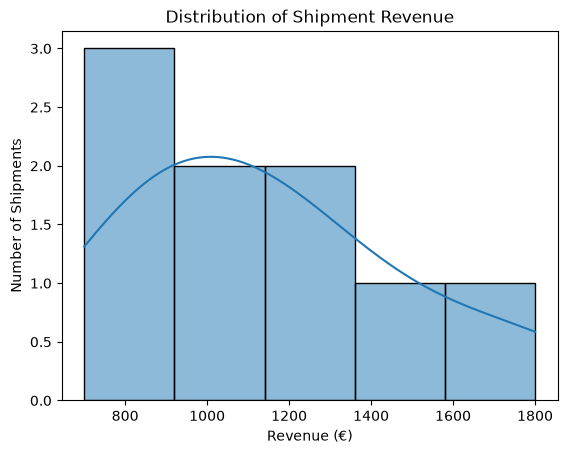

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create histogram
ax = sns.histplot(
    data = clean_shipments,
    x = "revenue",
    bins = 5,
    kde = True
)
# Add title and axis labels
plt.title("Distribution of Shipment Revenue")
plt.xlabel("Revenue (€)")
plt.ylabel("Number of Shipments")

# Display plot
plt.show()

## Exercise 02.10.03.04 — Detecting Outliers
Next, we'll use a boxplot to examine potential revenue outliers.

Your task is to create a horizontal boxplot using:
- sns.boxplot()
- data=clean_shipments
- x="revenue"
- A meaningful title and x-axis label

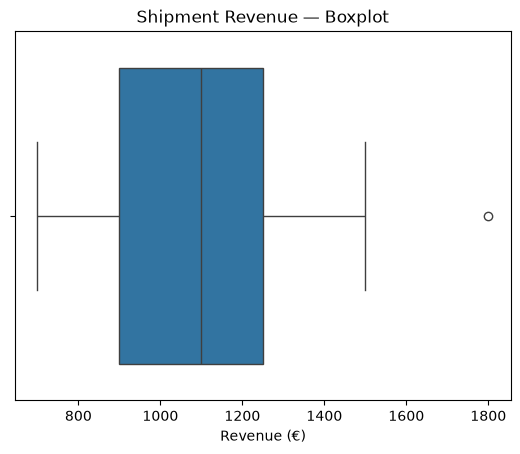

In [15]:

import matplotlib.pyplot as plt
import seaborn as sns

ax = sns.boxplot(
    data=clean_shipments,
    x="revenue"
)

plt.title("Shipment Revenue — Boxplot")
plt.xlabel("Revenue (€)")
plt.ylabel("")

plt.show()


## Exercise 02.10.03.05 — Calculate Outlier Thresholds in Python

In [16]:

revenue = clean_shipments["revenue"]

# 1. Calculate Q1 (25th percentile)
q1 = clean_shipments["revenue"].quantile(0.25)

# 2. Calculate Q3 (75th percentile)
q3 = clean_shipments["revenue"].quantile(0.75)

# 3. Calculate IQR
iqr = q3 - q1

# 4. Calculate lower and upper fences
upper_fence = q3 + 1.5 * iqr
lower_fence = q1 - 1.5 * iqr

# 5. Print the results
print(f"Q1: €{q1:.2f}")
print(f"Q3: €{q3:.2f}")
print(f"IQR: €{iqr:.2f}")
print(f"Lower fence: €{lower_fence:.2f}")
print(f"Upper fence: €{upper_fence:.2f}")

print("\nThis means a shipment with revenue above €1,775 is considered a potential upper outlier. Our shipment with €1,800 qualifies.")


Q1: €900.00
Q3: €1250.00
IQR: €350.00
Lower fence: €375.00
Upper fence: €1775.00

This means a shipment with revenue above €1,775 is considered a potential upper outlier. Our shipment with €1,800 qualifies.


## Exercise 02.10.03.06 — Identify Actual Outliers
Now that you've calculated the thresholds, let's identify which shipments are outliers.

Your task: Filter clean_shipments to return all rows where:
- Revenue is below lower_fence, OR
- Revenue is above upper_fence.

Use Boolean indexing with | (OR).

In [17]:
#Revenue below lower fence
lower_outliers = clean_shipments.loc[clean_shipments["revenue"] < lower_fence]
upper_outliers = clean_shipments.loc[clean_shipments["revenue"] > upper_fence]
outliers = clean_shipments.loc[(clean_shipments["revenue"] < lower_fence) | (clean_shipments["revenue"] > upper_fence)]
outliers

,shipment_id,customer,region,revenue,cost,delivery_days,delivery_status
7,1008,Zalando,North,1800.0,1200,6.0,Delayed


## 02.10.03.07 — Customer-Level Exploratory Analysis

Now we're moving from individual shipments to customer-level analytics.

Our logistics dataset contains three customers: Amazon, Zalando, and Otto.
Your task
Using clean_shipments, calculate the following metrics for each customer:
1. Shipment count — Number of shipments per customer.
2. Total revenue — Sum of revenue per customer.
3. Average revenue — Mean revenue per shipment.
4. Average delivery time — Mean delivery days per customer.

Use .groupby() and .agg() to calculate all four metrics in a single DataFrame.

In [18]:
customer_summary = (
    clean_shipments
    .groupby("customer")
    .agg(
        shipment_count=("shipment_id", "count"),
        total_revenue=("revenue", "sum"),
        avg_revenue=("revenue", "mean"),
        avg_delivery_days=("delivery_days", "mean")
    )
    .reset_index()
)

display(customer_summary)


,customer,shipment_count,total_revenue,avg_revenue,avg_delivery_days
0,Amazon,5,4050.0,1012.500000,2.75
1,Otto,3,2900.0,966.666667,3.00
2,Zalando,3,3300.0,1650.000000,5.50


## Exercise 02.10.03.08 — Customer Performance Ranking

Now let's turn our customer summary into a business insight.

Using your existing customer_summary DataFrame, complete these three tasks:

1. Sort customers by total_revenue, highest first.
2. Identify the customer with the highest avg_revenue.
3. Identify the customer with the highest avg_delivery_days (slowest average delivery).

In [19]:
revenue_ranking = customer_summary.sort_values("total_revenue",ascending=False)
highest_avg_revenue = customer_summary.loc[customer_summary["avg_revenue"].idxmax()]
slowest_customer = customer_summary.loc[customer_summary["avg_delivery_days"].idxmax()]

display(revenue_ranking)
display(highest_avg_revenue)
display(slowest_customer)

,customer,shipment_count,total_revenue,avg_revenue,avg_delivery_days
0,Amazon,5,4050.0,1012.500000,2.75
2,Zalando,3,3300.0,1650.000000,5.50
1,Otto,3,2900.0,966.666667,3.00


customer             Zalando
shipment_count             3
total_revenue         3300.0
avg_revenue           1650.0
avg_delivery_days        5.5
Name: 2, dtype: object

customer             Zalando
shipment_count             3
total_revenue         3300.0
avg_revenue           1650.0
avg_delivery_days        5.5
Name: 2, dtype: object

## Exercise 02.10.03.09 — Regional Performance Analysis

Now let's analyze operational performance across regions.

Using clean_shipments, create a region_summary DataFrame containing:
1. shipment_count — Number of shipments per region.
2. total_revenue — Total revenue per region.
3. avg_delivery_days — Average delivery time per region.
4. delayed_shipments — Number of shipments with delivery_status == "Delayed".

For the fourth metric, you can use a lambda function:

In [20]:
clean_shipments

,shipment_id,customer,region,revenue,cost,delivery_days,delivery_status
0,1001,Amazon,North,1200.0,800,2.0,Delivered
1,1002,Amazon,South,850.0,600,3.0,Delivered
2,1003,Zalando,North,1500.0,1000,5.0,Delayed
3,1004,Otto,East,700.0,500,2.0,Delivered
4,1005,Zalando,West,NaN,750,NaN,Delayed
5,1006,Amazon,South,1100.0,850,4.0,Delivered
6,1007,Otto,East,950.0,700,3.0,Delivered
7,1008,Zalando,North,1800.0,1200,6.0,Delayed
8,1009,Amazon,West,NaN,650,2.0,Delivered
9,1010,Otto,South,1250.0,900,4.0,Delayed


In [21]:
region_summary = (
    clean_shipments
    .groupby("region")
    .agg(
        shipment_count = ("shipment_id", "count"),
        total_revenue = ("revenue","sum"),
        avg_delivery_days =("delivery_days","mean"),
        delayed_shipments=(
        "delivery_status",
        lambda x: (x == "Delayed").sum()
)

    )
    .reset_index()
)
region_summary

,region,shipment_count,total_revenue,avg_delivery_days,delayed_shipments
0,East,3,2550.0,2.500000,0
1,North,3,4500.0,4.333333,2
2,South,3,3200.0,3.666667,1
3,West,2,0.0,2.000000,1


## 02.10.03.10 — Regional Delay Rate

In [22]:

region_summary["delay_rate_pct"] = (
    region_summary["delayed_shipments"]
    / region_summary["shipment_count"]
    * 100
).round(2)

region_ranking = region_summary.sort_values(
    "delay_rate_pct",
    ascending=False
)

display(region_ranking)


,region,shipment_count,total_revenue,avg_delivery_days,delayed_shipments,delay_rate_pct
1,North,3,4500.0,4.333333,2,66.67
3,West,2,0.0,2.000000,1,50.00
2,South,3,3200.0,3.666667,1,33.33
0,East,3,2550.0,2.500000,0,0.00


## Exercise 02.10.03.11 — Visualizing Regional Delay Rates

Now let's visualize the regional performance differences.

Create a vertical bar chart showing delay rate (%) by region, using region_ranking.

Your requirements:
1. Use sns.barplot().
2. Put region on the x-axis.
3. Put delay_rate_pct on the y-axis.
4. Add the title "Regional Delivery Delay Rates".
5. Label the axes appropriately.
6. Display the chart.

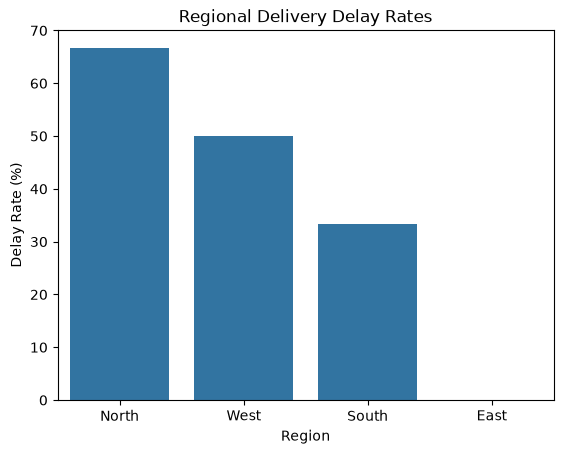

In [23]:
ax = sns.barplot(
    data=region_ranking,
    x="region",
    y="delay_rate_pct"
)

plt.title("Regional Delivery Delay Rates")
plt.xlabel("Region")
plt.ylabel("Delay Rate (%)")

plt.show()

## 02.10.04 — Operational & Financial KPIs

We're now moving from exploratory analysis to business performance measurement.

In logistics, revenue alone doesn't tell us whether a shipment is profitable. We also need to examine costs, profit, and margins.

### Three important financial KPIs

| KPI | Formula | Interpretation |
| :--- | :--- | :--- |
| **Revenue** | Shipment revenue | Money earned |
| **Profit** | Revenue − Cost | Money remaining after costs |
| **Profit margin** | Profit / Revenue × 100 | Percentage of revenue retained as profit |

For example, consider a shipment with €1,200 revenue and €800 cost:

$$\text{Profit} = 1200 - 800 = €400$$

$$\text{Profit Margin} = \frac{400}{1200} \times 100 = 33.33\%$$

---

### Exercise 02.10.04.01 — Shipment-Level Profitability

Using `financial_shipments`, calculate two new columns:
1. `profit` — Revenue minus cost.
2. `profit_margin_pct` — Profit divided by revenue, multiplied by 100 and rounded to two decimal places.

Then display the following columns:
`shipment_id`, `customer`, `revenue`, `cost`, `profit`, `profit_margin_pct`


In [24]:
financial_shipments["profit"] =  financial_shipments["revenue"] - financial_shipments["cost"]
financial_shipments["profit_margin_pct"] =  (financial_shipments["profit"] / financial_shipments["revenue"] * 100).round(2)

display(
    financial_shipments[
        [
            "shipment_id",
            "customer",
            "revenue",
            "cost",
            "profit",
            "profit_margin_pct"
        ]
    ]
)

,shipment_id,customer,revenue,cost,profit,profit_margin_pct
0,1001,Amazon,1200.0,800,400.0,33.33
1,1002,Amazon,850.0,600,250.0,29.41
2,1003,Zalando,1500.0,1000,500.0,33.33
3,1004,Otto,700.0,500,200.0,28.57
5,1006,Amazon,1100.0,850,250.0,22.73
6,1007,Otto,950.0,700,250.0,26.32
7,1008,Zalando,1800.0,1200,600.0,33.33
9,1010,Otto,1250.0,900,350.0,28.00
10,1011,Amazon,900.0,650,250.0,27.78


## Exercise 02.10.04.02 — Overall Financial KPIs

Now let's calculate the financial performance of the entire logistics operation.

Using financial_shipments, calculate:
1. total_revenue — Sum of all revenue.
2. total_cost — Sum of all costs.
3. total_profit — Total revenue minus total cost.
4. overall_profit_margin_pct — Total profit divided by total revenue × 100.

Important: The overall profit margin should be calculated from the totals, not by averaging individual shipment margins.

In [25]:
total_revenue = financial_shipments["revenue"].sum()
total_cost = financial_shipments["cost"].sum()
total_profit = financial_shipments["profit"].sum()
overall_profit_margin_pct = total_profit / total_revenue * 100

print(f"Total revenue: €{total_revenue:,.2f}")
print(f"Total cost: €{total_cost:,.2f}")
print(f"Total profit: €{total_profit:,.2f}")
print(f"Overall profit margin: {overall_profit_margin_pct:.2f}%")


Total revenue: €10,250.00
Total cost: €7,200.00
Total profit: €3,050.00
Overall profit margin: 29.76%


## Exercise 02.10.04.03 — Customer Profitability

Now let's calculate financial performance for each customer.

Using financial_shipments, create a DataFrame called customer_profitability containing:
1. total_revenue — Sum of revenue per customer.
2. total_cost — Sum of costs per customer.
3. total_profit — Sum of profit per customer.
4. profit_margin_pct — Calculate from aggregated total profit and total revenue, rounded to two decimals.

Then sort customers by total_profit in descending order.

In [26]:
# Step 1: Aggregate financial KPIs
customer_profitability = (
    financial_shipments
    .groupby("customer")
    .agg(
        total_revenue=("revenue", "sum"),
        total_cost=("cost", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

# Step 2: Calculate profit margin
customer_profitability["profit_margin_pct"] = (
    customer_profitability["total_profit"]
    / customer_profitability["total_revenue"]
    * 100
).round(2)

# Step 3: Sort by total profit
customer_profitability = customer_profitability.sort_values(
    "total_profit",
    ascending=False
)

# Step 4: Display
display(customer_profitability)


,customer,total_revenue,total_cost,total_profit,profit_margin_pct
0,Amazon,4050.0,2900,1150.0,28.40
2,Zalando,3300.0,2200,1100.0,33.33
1,Otto,2900.0,2100,800.0,27.59


# Exercise 02.10.04.04 — Regional Profitability

Now apply the same logic to regions instead of customers.

Using financial_shipments, create a DataFrame called regional_profitability containing:
1. total_revenue — Sum of revenue per region.
2. total_cost — Sum of costs per region.
3. total_profit — Sum of profit per region.
4. profit_margin_pct — Total profit divided by total revenue × 100, rounded to two decimals.

Then sort regions by profit_margin_pct in descending order.

In [27]:
financial_shipments

,shipment_id,customer,region,revenue,cost,delivery_days,delivery_status,profit,profit_margin_pct
0,1001,Amazon,North,1200.0,800,2.0,Delivered,400.0,33.33
1,1002,Amazon,South,850.0,600,3.0,Delivered,250.0,29.41
2,1003,Zalando,North,1500.0,1000,5.0,Delayed,500.0,33.33
3,1004,Otto,East,700.0,500,2.0,Delivered,200.0,28.57
5,1006,Amazon,South,1100.0,850,4.0,Delivered,250.0,22.73
6,1007,Otto,East,950.0,700,3.0,Delivered,250.0,26.32
7,1008,Zalando,North,1800.0,1200,6.0,Delayed,600.0,33.33
9,1010,Otto,South,1250.0,900,4.0,Delayed,350.0,28.00
10,1011,Amazon,East,900.0,650,NaN,Delivered,250.0,27.78


In [28]:
# Step 1: Aggregate financial KPIs
regional_profitability = (
    financial_shipments
    .groupby("region")
    .agg(
        total_revenue=("revenue", "sum"),
        total_cost=("cost", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

# Step 2: Calculate profit margin
regional_profitability["profit_margin_pct"] = (
    regional_profitability["total_profit"]
    / regional_profitability["total_revenue"]
    * 100
).round(2)

# Step 3: Sort by total profit
regional_profitability = regional_profitability.sort_values(
    "total_profit",
    ascending=False
)

# Step 4: Display
display(regional_profitability)


,region,total_revenue,total_cost,total_profit,profit_margin_pct
1,North,4500.0,3000,1500.0,33.33
2,South,3200.0,2350,850.0,26.56
0,East,2550.0,1850,700.0,27.45


## Exercise 02.10.04.05 — Financial vs. Operational Performance

Now let's combine two dimensions of business performance:
- Financial performance: Profit margin by region.
- Operational performance: Delay rate by region.
Your task is to merge regional_profitability with region_summary.

Use .merge() to create a new DataFrame named regional_performance containing:
1. region
2. total_revenue
3. total_profit
4. profit_margin_pct
5. delay_rate_pct

Use an inner join on the region column.

In [31]:
regional_performance = pd.merge(
    regional_profitability[
        ["region", "total_revenue", "total_profit", "profit_margin_pct"]
    ],
    region_summary[
        ["region", "delay_rate_pct"]
    ],
    on="region",
    how="inner"
)

display(regional_performance)


,region,total_revenue,total_profit,profit_margin_pct,delay_rate_pct
0,North,4500.0,1500.0,33.33,66.67
1,South,3200.0,850.0,26.56,33.33
2,East,2550.0,700.0,27.45,0.00


## Exercise 02.10.04.06 — Correlation Analysis

Your task
Using regional_performance:
1. Calculate the Pearson correlation between profit_margin_pct and delay_rate_pct.
2. Store the result in a variable named correlation.
3. Print the result rounded to three decimal places.

In [37]:
correlation = (regional_performance["profit_margin_pct"].corr(regional_performance["delay_rate_pct"]))
print(f"Correlation: {correlation:.3f}")

Correlation: 0.799


## Exercise 02.10.04.07 — Operational KPI: On-Time Delivery Rate

Next, we'll calculate a fundamental logistics performance metric.

$$\text{On-Time Delivery Rate}=\frac{\text{Delivered Shipments}}{\text{Total Shipments}}\times100$$

For this exercise, we'll treat `delivery_status == "Delivered"` as on-time delivery.

**Your task:**
Using `clean_shipments`, calculate:
1. `total_shipments` — Total number of shipments.
2. `delivered_shipments` — Number of shipments with status `"Delivered"`.
3. `on_time_delivery_rate` — Percentage delivered, rounded to two decimal places.


In [38]:
clean_shipments

,shipment_id,customer,region,revenue,cost,delivery_days,delivery_status
0,1001,Amazon,North,1200.0,800,2.0,Delivered
1,1002,Amazon,South,850.0,600,3.0,Delivered
2,1003,Zalando,North,1500.0,1000,5.0,Delayed
3,1004,Otto,East,700.0,500,2.0,Delivered
4,1005,Zalando,West,NaN,750,NaN,Delayed
5,1006,Amazon,South,1100.0,850,4.0,Delivered
6,1007,Otto,East,950.0,700,3.0,Delivered
7,1008,Zalando,North,1800.0,1200,6.0,Delayed
8,1009,Amazon,West,NaN,650,2.0,Delivered
9,1010,Otto,South,1250.0,900,4.0,Delayed


In [60]:
total_shipments = len(clean_shipments)
delivered_shipments = (clean_shipments["delivery_status"] == "Delivered").sum()
on_time_delivery_rate = delivered_shipments / total_shipments * 100
print(f"Total Number of Shipments: {total_shipments}")
print(f"Total Number of delivered Shipments {delivered_shipments}")
print(f"On Time Delivery Rate: {on_time_delivery_rate}")

Total Number of Shipments: 11
Total Number of delivered Shipments 7
On Time Delivery Rate: 63.63636363636363


In [64]:
delayed_shipments = (clean_shipments["delivery_status"] == "Delayed").sum()
delay_rate_pct = delayed_shipments / total_shipments * 100
display(delay_rate_pct)

np.float64(36.36363636363637)

## Next: 02.10.05 — Customer & Regional Performance

### Exercise 02.10.05.01 — Customer Delay Rate

We have calculated the overall delay rate. Now management wants to know which customer experiences the highest proportion of delayed shipments.

Using `clean_shipments`, create a DataFrame called `customer_delivery_performance` containing:

| customer | total_shipments | delayed_shipments | delay_rate_pct |
| :--- | :--- | :--- | :--- |
| Amazon | … | … | … |
| Otto | … | … | … |
| Zalando | … | … | … |

**Your tasks are to:**
* Group shipments by customer.
* Count all shipments.
* Count those with `"Delayed"` status.
* Calculate the delay rate as a percentage rounded to two decimal places.


In [70]:
customer_delivery_performance = (
    clean_shipments
    .groupby("customer")
    .agg(
        total_shipments=("shipment_id", "count"),
        delayed_shipments=(
            "delivery_status",
            lambda x: (x == "Delayed").sum()
        )
    )
    .reset_index()
)

customer_delivery_performance["delay_rate_pct"] = (
    customer_delivery_performance["delayed_shipments"]
    / customer_delivery_performance["total_shipments"]
    * 100
).round(2)

display(customer_delivery_performance)


,customer,total_shipments,delayed_shipments,delay_rate_pct
0,Amazon,5,0,0.00
1,Otto,3,1,33.33
2,Zalando,3,3,100.00


# Exercise 02.10.05.02 — Customer Profitability vs. Delivery Performance

**Business question:** Are our most profitable customers also receiving the best delivery service?

We already have two DataFrames:
* `customer_profitability` — Financial performance by customer.
* `customer_delivery_performance` — Operational performance by customer.

Your task is to combine them into a single management-ready table.

## Expected structure

| customer | total_revenue | total_profit | profit_margin_pct | delay_rate_pct |
| :--- | :--- | :--- | :--- | :--- |
| Amazon | … | … | … | … |
| Otto | … | … | … | … |
| Zalando | … | … | … | … |

## Your coding task

1. Merge both DataFrames using `customer` as the key and `how="inner"`.
2. Avoid duplicate-column issues by selecting only the required columns before merging.
3. Store the result in `customer_performance`.
4. Sort customers by `total_profit` in descending order.


In [71]:
customer_profitability

,customer,total_revenue,total_cost,total_profit,profit_margin_pct
0,Amazon,4050.0,2900,1150.0,28.40
2,Zalando,3300.0,2200,1100.0,33.33
1,Otto,2900.0,2100,800.0,27.59


In [72]:
customer_delivery_performance

,customer,total_shipments,delayed_shipments,delay_rate_pct
0,Amazon,5,0,0.00
1,Otto,3,1,33.33
2,Zalando,3,3,100.00


In [78]:
customer_performance = pd.merge(
    customer_profitability[
        ["customer","total_revenue","total_profit","profit_margin_pct"]
    ],
    customer_delivery_performance[
        ["customer","delay_rate_pct"]
    ],
    on="customer",
    how="inner"
)
customer_performance = customer_performance.sort_values("total_profit", ascending=False)
customer_performance

,customer,total_revenue,total_profit,profit_margin_pct,delay_rate_pct
0,Amazon,4050.0,1150.0,28.40,0.00
1,Zalando,3300.0,1100.0,33.33,100.00
2,Otto,2900.0,800.0,27.59,33.33


## Exercise 02.10.05.03 — Identify High-Risk Customers
Now we'll use the merged dataset to identify customers who are financially important but operationally underserved.

Imagine management defines a high-risk customer as one meeting both conditions:
- total_revenue greater than €2,500
- delay_rate_pct greater than 30%
Your task
Create a DataFrame named high_risk_customers containing only customers who satisfy both conditions.

In [90]:
high_risk_customers = customer_performance[
    (customer_performance["total_revenue"] > 2500) & 
    (customer_performance["delay_rate_pct"]>30)
]

In [82]:
high_risk_customers

,customer,total_revenue,total_profit,profit_margin_pct,delay_rate_pct
0,Amazon,4050.0,1150.0,28.40,0.00
1,Zalando,3300.0,1100.0,33.33,100.00
2,Otto,2900.0,800.0,27.59,33.33


## Exercise 02.10.05.04 — Customer Risk Classification
Instead of creating a separate DataFrame containing only high-risk customers, management now wants every customer assigned a risk category.

We'll use np.where(), a NumPy function that applies conditional logic.

Its syntax is: 

**np.where(condition, value_if_true, value_if_false)**

Your task
Create a new column called risk_category in customer_performance.

Assign:
- "High Risk" if revenue exceeds €2,500 and the delay rate exceeds 30%.
- "Low Risk" otherwise.

In [95]:
customer_performance["risk_category"] = np.where(
        (customer_performance["total_revenue"] > 2500) & (customer_performance["delay_rate_pct"]>30),
    "High Risk",
    "Low Risk"
)
customer_performance

,customer,total_revenue,total_profit,profit_margin_pct,delay_rate_pct,risk_category
0,Amazon,4050.0,1150.0,28.40,0.00,Low Risk
1,Zalando,3300.0,1100.0,33.33,100.00,High Risk
2,Otto,2900.0,800.0,27.59,33.33,High Risk


## Exercise 02.10.05.05 — Customer Risk Summary
Management now wants an aggregated overview of the customer portfolio by risk category.

Business question: How much revenue and profit are associated with high-risk versus low-risk customers?

In [97]:
customer_risk_summary = (
    customer_performance
    .groupby("risk_category")
    .agg(
        customer_count=("customer", "count"),
        total_revenue=("total_revenue", "sum"),
        total_profit=("total_profit", "sum"),
        avg_delay_rate_pct=("delay_rate_pct", "mean")
    )
    .reset_index()
)

customer_risk_summary["avg_delay_rate_pct"] = (
    customer_risk_summary["avg_delay_rate_pct"].round(2)
)

display(customer_risk_summary)


,risk_category,customer_count,total_revenue,total_profit,avg_delay_rate_pct
0,High Risk,2,6200.0,1900.0,66.66
1,Low Risk,1,4050.0,1150.0,0.00


## Exercise 02.10.06.01 — Customer Profitability Visualization

Your requirements
1. Use the existing customer_performance DataFrame.
2. Create a vertical bar chart using Seaborn (sns.barplot()).
3. Display customer on the x-axis and total_profit on the y-axis.
4. Sort customers by total profit in descending order.
5. Add the title "Total Profit by Customer".
6. Label both axes appropriately, including euros (€).
7. Set the figure size to (9, 5) and display the chart.

In [98]:
customer_performance

,customer,total_revenue,total_profit,profit_margin_pct,delay_rate_pct,risk_category
0,Amazon,4050.0,1150.0,28.40,0.00,Low Risk
1,Zalando,3300.0,1100.0,33.33,100.00,High Risk
2,Otto,2900.0,800.0,27.59,33.33,High Risk


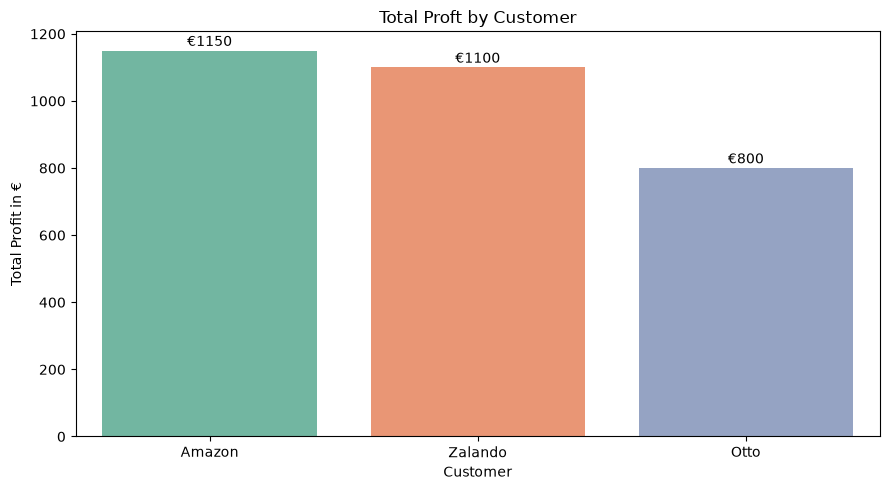

In [118]:
plot_data = customer_performance.sort_values("total_profit", ascending=False)

plt.figure(figsize=(9,5))

ax = sns.barplot(
    data = plot_data,
    x="customer",
    y = "total_profit",
    hue="customer",
    palette="Set2",
    legend=False

)

for container in ax.containers:
    ax.bar_label(container, fmt="€%.0f", padding=1)



ax.set_title("Total Proft by Customer")
ax.set_xlabel("Customer")
ax.set_ylabel("Total Profit in €")

plt.tight_layout()
plt.show()

## Exercise 02.10.06.02 — Regional Delivery Performance.

Your task
Create a horizontal bar chart showing which regions have the highest delivery delay rates.

Use region_summary and meet these requirements:
1. Sort regions by delay_rate_pct, descending.
2. Create a horizontal bar chart with sns.barplot().
3. Set the figure size to (9, 5).
4. Add the title "Delivery Delay Rate by Region".
5. Label both axes appropriately.
6. Give each region a different color using hue="region".
7. Display the chart.

In [119]:
regional_performance

,region,total_revenue,total_profit,profit_margin_pct,delay_rate_pct
0,North,4500.0,1500.0,33.33,66.67
1,South,3200.0,850.0,26.56,33.33
2,East,2550.0,700.0,27.45,0.00


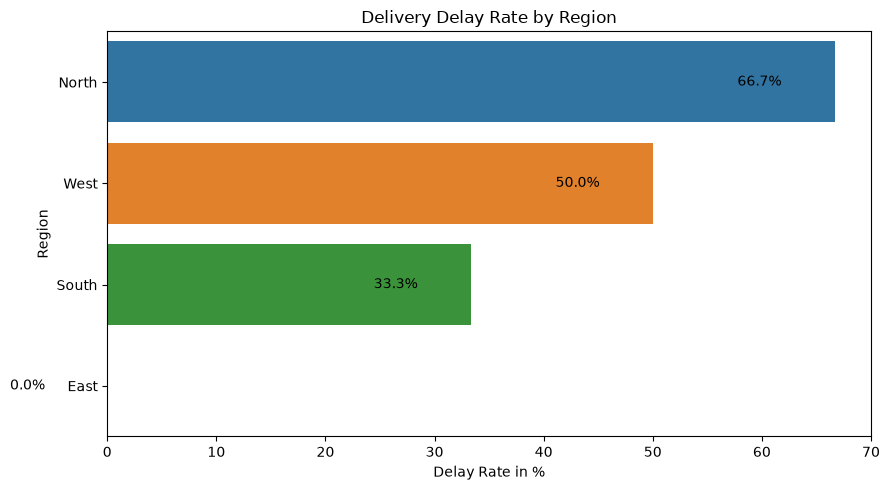

In [136]:
plt.figure(figsize=(9,5))

plot_data2 = region_summary.sort_values("delay_rate_pct", ascending=False)

ax2 = sns.barplot(
    data=plot_data2,
    x = "delay_rate_pct",
    y = "region",
    hue="region"


)
ax2.set_title("Delivery Delay Rate by Region")
ax2.set_xlabel("Delay Rate in %")
ax2.set_ylabel("Region")
for container in ax2.containers:
    ax2.bar_label(container, fmt="%.1f%%", padding=-70)

plt.tight_layout()
plt.show()

## 02.10.06.03 — Financial vs. Operational Performance

Business scenario: Management wants to understand whether regions with higher profit margins also experience higher delivery delay rates.

You've already calculated the Pearson correlation. Now we'll visualize that relationship using a scatter plot.

Your task
Using regional_performance, create a scatter plot with the following requirements:
1. Set the figure size to (9, 5).
2. Use sns.scatterplot().
3. Put profit_margin_pct on the x-axis.
4. Put delay_rate_pct on the y-axis.
5. Use hue="region" to distinguish regions by color.
6. Set the point size to s=150.
7. Add the title "Profit Margin vs. Delivery Delay Rate".
8. Label both axes with their percentages.
9. Display the chart.

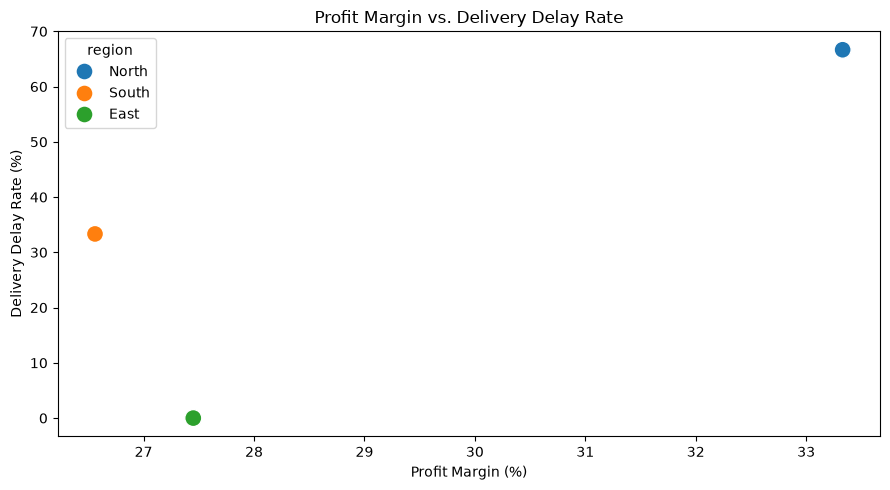

In [146]:
plt.figure(figsize=(9, 5))

ax3 = sns.scatterplot(
    data=regional_performance,
    x="profit_margin_pct",
    y="delay_rate_pct",
    hue="region",
    s=150
)

ax3.set_title("Profit Margin vs. Delivery Delay Rate")
ax3.set_xlabel("Profit Margin (%)")
ax3.set_ylabel("Delivery Delay Rate (%)")

plt.tight_layout()
plt.show()


In [139]:
regional_performance

,region,total_revenue,total_profit,profit_margin_pct,delay_rate_pct
0,North,4500.0,1500.0,33.33,66.67
1,South,3200.0,850.0,26.56,33.33
2,East,2550.0,700.0,27.45,0.00


## Exercise 02.10.06.04 — Customer Profitability vs. Delivery Risk
Business scenario: Management wants to identify customers who generate substantial profits but experience poor delivery performance.

We'll create a scatter plot that combines three business dimensions:
- X-axis: Customer profit margin (%)
- Y-axis: Customer delay rate (%)
- Bubble size: Total revenue (€)
This is called a bubble chart.
Your task
Use the existing customer_performance DataFrame.
1. Create a figure with size (10, 6).
2. Use sns.scatterplot().
3. Set x="profit_margin_pct" and y="delay_rate_pct".
4. Use hue="customer" to distinguish customers.
5. Use size="total_revenue" to make bubble sizes proportional to revenue.
6. Set sizes=(100, 600) to control the marker size range.
7. Add the title "Customer Profitability vs. Delivery Risk".
8. Label both axes with %.
9. Display the chart.

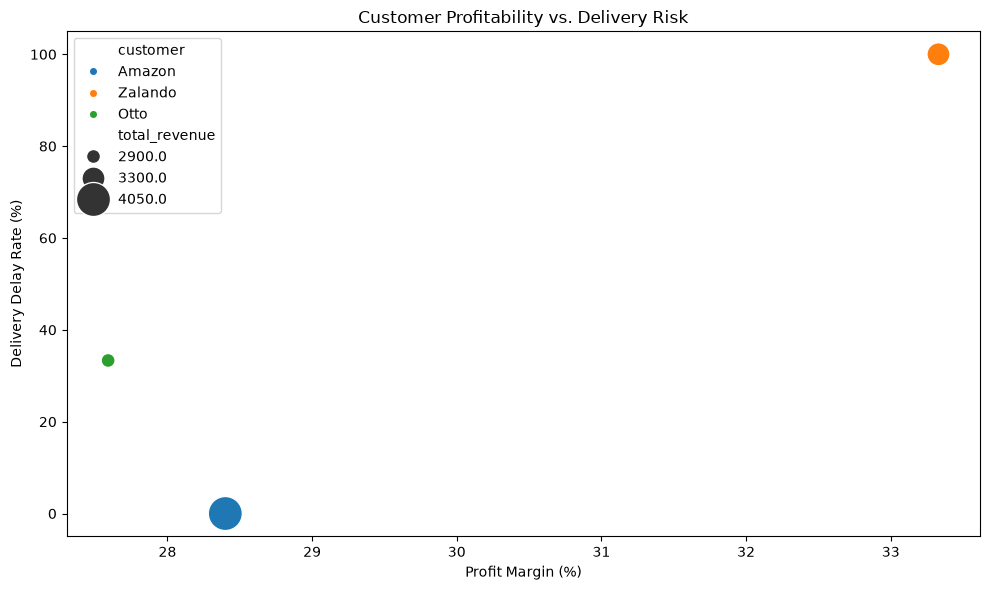

In [156]:
plt.figure(figsize=(10,6))

ax4 = sns.scatterplot(
    data=customer_performance,
    x="profit_margin_pct",
    y="delay_rate_pct",
    hue="customer",
    size="total_revenue",
    sizes=(100,600)
)

ax4.set_title("Customer Profitability vs. Delivery Risk")
ax4.set_xlabel("Profit Margin (%)")
ax4.set_ylabel("Delivery Delay Rate (%)")

plt.tight_layout()
plt.show()

In [148]:
customer_performance

,customer,total_revenue,total_profit,profit_margin_pct,delay_rate_pct,risk_category
0,Amazon,4050.0,1150.0,28.40,0.00,Low Risk
1,Zalando,3300.0,1100.0,33.33,100.00,High Risk
2,Otto,2900.0,800.0,27.59,33.33,High Risk


## Exercise 02.10.06.05 — Revenue and Profit Comparison
This is our final exercise in the Visualization & Storytelling section.

Business question: Which customers generate the most revenue, and how much of that revenue becomes profit?

Create a grouped bar chart comparing total revenue and total profit for each customer.
Requirements
1. Use customer_performance.
2. Reshape the DataFrame using pd.melt().
3. Keep customer as the identifier.
4. Convert total_revenue and total_profit into a single numerical column called amount.
5. Create a grouped bar chart using sns.barplot().
6. Use hue to distinguish revenue and profit.
7. Add a title, axis labels, and legend.

In [160]:
customer_performance

,customer,total_revenue,total_profit,profit_margin_pct,delay_rate_pct,risk_category
0,Amazon,4050.0,1150.0,28.40,0.00,Low Risk
1,Zalando,3300.0,1100.0,33.33,100.00,High Risk
2,Otto,2900.0,800.0,27.59,33.33,High Risk


In [159]:
plot_data = pd.melt(
    customer_performance,
    id_vars="customer",
    value_vars=["total_revenue", "total_profit"],
    var_name="metric",
    value_name="amount"
)

display(plot_data)

,customer,metric,amount
0,Amazon,total_revenue,4050.0
1,Zalando,total_revenue,3300.0
2,Otto,total_revenue,2900.0
3,Amazon,total_profit,1150.0
4,Zalando,total_profit,1100.0
5,Otto,total_profit,800.0


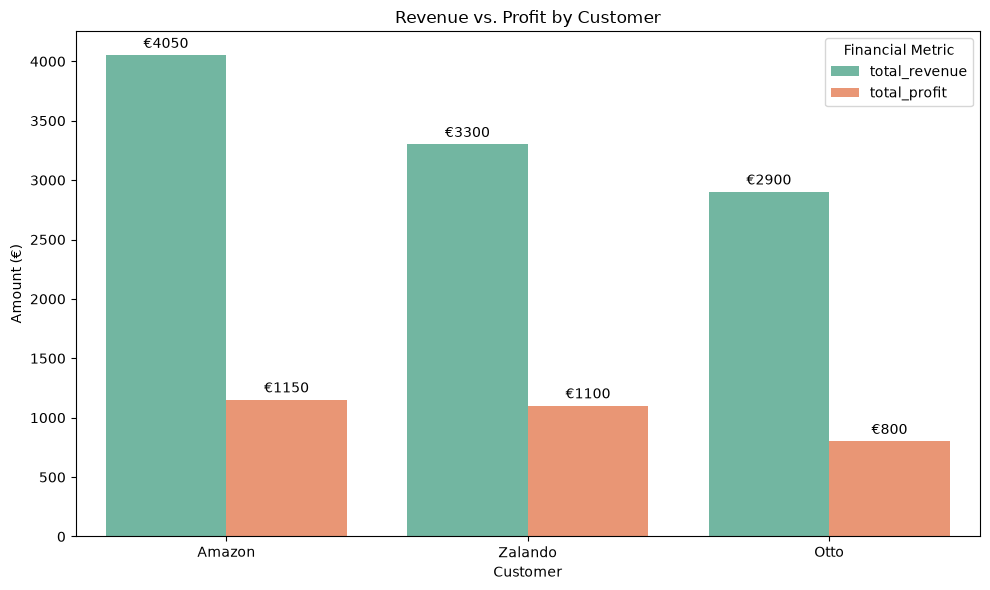

In [161]:
# 2. Create grouped bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_data,
    x="customer",
    y="amount",
    hue="metric",
    palette="Set2"
)

# 3. Add title and axis labels
ax.set_title("Revenue vs. Profit by Customer")
ax.set_xlabel("Customer")
ax.set_ylabel("Amount (€)")

# 4. Format legend
ax.legend(title="Financial Metric")

# 5. Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="€%.0f", padding=3)

# 6. Display chart
plt.tight_layout()
plt.show()


## Exercise 02.10.07.01 — Create a Data Cleaning Function
Your task: Convert our existing data-cleaning logic into a reusable function called clean_shipment_data().

The function should:
1. Accept a Pandas DataFrame named df.
2. Create a copy to avoid modifying the original data.
3. Remove duplicate rows and reset the index.
4. Standardize customer using .str.strip().str.title().
5. Standardize delivery_status using .str.title().
6. Convert revenue to numeric using pd.to_numeric(..., errors="coerce").
7. Return the cleaned DataFrame.

In [164]:
raw_shipments

,shipment_id,customer,region,revenue,cost,delivery_days,delivery_status
0,1001,Amazon,North,1200,800,2.0,Delivered
1,1002,amazon,South,850,600,3.0,delivered
2,1003,Zalando,North,1500,1000,5.0,Delayed
3,1004,OTTO,East,700,500,2.0,Delivered
4,1005,zalando,West,invalid,750,NaN,DELAYED
5,1006,Amazon,South,1100,850,4.0,Delivered
6,1007,Otto,East,950,700,3.0,delivered
7,1008,ZALANDO,North,1800,1200,6.0,Delayed
8,1009,amazon,West,NaN,650,2.0,Delivered
9,1010,Otto,South,1250,900,4.0,delayed


In [168]:
def clean_shipment_data(df):
    """
    Clean raw shipment data and return a new DataFrame.
    """

    # 1. Create a copy
    cleaned = df.copy()

    # 2. Remove duplicate rows and reset index
    cleaned = cleaned.drop_duplicates().reset_index(drop=True)

    # 3. Standardize customer names
    cleaned["customer"] = cleaned["customer"].str.strip().str.title()

    # 4. Standardize delivery statuses
    cleaned["delivery_status"] = cleaned["delivery_status"].str.lower().str.strip().str.title()

    # 5. Convert revenue to numeric
    cleaned["revenue"] = pd.to_numeric(
        cleaned["revenue"],
        errors="coerce"
        )

    # 6. Return cleaned data
    return cleaned


# Test the function on our original dataset
test_cleaned = clean_shipment_data(raw_shipments)

display(test_cleaned.head())


,shipment_id,customer,region,revenue,cost,delivery_days,delivery_status
0,1001,Amazon,North,1200.0,800,2.0,Delivered
1,1002,Amazon,South,850.0,600,3.0,Delivered
2,1003,Zalando,North,1500.0,1000,5.0,Delayed
3,1004,Otto,East,700.0,500,2.0,Delivered
4,1005,Zalando,West,NaN,750,NaN,Delayed


## Exercise 02.10.07.02 — Data Validation with Assertions
Now we need to verify that the cleaning function actually works.

In professional analytics, data validation is essential. A pipeline should detect unexpected results rather than silently producing incorrect KPIs.
Your task
Using test_cleaned, write four assertions:
1. The cleaned DataFrame contains exactly 11 rows.
2. There are no duplicate rows.
3. The revenue column has a numeric data type.
4. Every customer name belongs to the expected set: {"Amazon", "Otto", "Zalando"}.

In [176]:
clean_shipments.duplicated().sum()

np.int64(0)

In [181]:
assert len(test_cleaned) == 11
assert test_cleaned.duplicated().sum() == 0
assert pd.api.types.is_numeric_dtype(test_cleaned["revenue"])
valid_customers = {"Amazon", "Otto", "Zalando"}
assert test_cleaned["customer"].isin(valid_customers).all()


## Exercise 02.10.07.03 — Reusable KPI Calculation Function

Objective

Previously, we calculated financial KPIs directly in our notebook. Now we'll encapsulate those calculations in a reusable function.

Your function should:
1. Accept a cleaned shipment DataFrame (df).
2. Exclude shipments with missing revenue.
3. Calculate profit = revenue - cost.
4. Calculate profit_margin_pct = profit / revenue * 100, rounded to two decimals.
5. Return the resulting financial DataFrame.

In [183]:
def calculate_financial_kpis(df):
    """
    Calculate financial KPIs for shipments
    with valid revenue.
    """

    # 1. Exclude rows with missing revenue
    financial = (
        df
        .dropna(subset=["revenue"])
        .copy()
    )

    # 2. Calculate profit
    financial["profit"] = financial["revenue"] - financial["cost"]

    # 3. Calculate profit margin (%)
    financial["profit_margin_pct"] = financial["profit"] / financial["revenue"] *100

    # 4. Return financial DataFrame
    return financial


# Test your function
financial_result = calculate_financial_kpis(test_cleaned)

display(financial_result.head())


,shipment_id,customer,region,revenue,cost,delivery_days,delivery_status,profit,profit_margin_pct
0,1001,Amazon,North,1200.0,800,2.0,Delivered,400.0,33.333333
1,1002,Amazon,South,850.0,600,3.0,Delivered,250.0,29.411765
2,1003,Zalando,North,1500.0,1000,5.0,Delayed,500.0,33.333333
3,1004,Otto,East,700.0,500,2.0,Delivered,200.0,28.571429
5,1006,Amazon,South,1100.0,850,4.0,Delivered,250.0,22.727273


## Exercise 02.10.07.04 — Build an End-to-End Analytics Pipeline
Exercise 04 of 05
Now we combine your two reusable functions into a single pipeline.

Objective: Create run_analytics_pipeline(df) that accepts raw shipment data and returns two DataFrames: cleaned shipments and financial shipments.

In [188]:

def run_analytics_pipeline(df):
    """
    Run the complete shipment analytics pipeline.

    Returns:
        cleaned: Cleaned shipment DataFrame
        financial: Financial KPI DataFrame
    """

    # 1. Clean raw shipment data
    cleaned = clean_shipment_data(df)

    # 2. Calculate financial KPIs
    financial = calculate_financial_kpis(cleaned)

    # 3. Return both DataFrames
    return cleaned, financial


# Test the pipeline
cleaned_result, financial_result = run_analytics_pipeline(
    raw_shipments
)

print("Cleaned shipments:", len(cleaned_result))
print("Financial shipments:", len(financial_result))
print("Total profit:", financial_result["profit"].sum())


Cleaned shipments: 11
Financial shipments: 9
Total profit: 3050.0


In [ ]:
def test_analytics_pipeline():
    original = raw_shipments.copy(deep=True)

    # Run the pipeline
    cleaned, financial = test_analytics_pipeline(original)

    # Check row counts
    assert len(cleaned_result) == 11

    # Check financial results
    assert len(financial_result) == 9

    # Verify original data is unchanged
    pd.testing.assert_frame_equal(..., ...)

    print("All pipeline tests passed!")


test_analytics_pipeline()


TypeError: test_analytics_pipeline() takes 0 positional arguments but 1 was given